# Wave Equation, 1D

## Problem
$$
u_{tt} = u_{xx}, \quad 0<x<1, \quad u(x,0)=\sin(\pi x), \quad u_t(x,0)=0, \quad u(0,t)=u(1,t)=0
$$
Exact solution $u = \cos(\pi t)\sin(\pi x)$.

## Discretization
Three-level explicit scheme with $\sigma = \Delta t / h$

$$
u_i^{n+1} = 2u_i^n - u_i^{n-1} + \sigma^2\left(u_{i-1}^n - 2u_i^n + u_{i+1}^n\right)
$$

The first step is $u^1 = u^0 + \frac{\Delta t^2}{2} u^0_{xx}$. Stability needs $\sigma \le 1$.

## Code

In [1]:
import sys
sys.path.insert(0, '../src')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from wave import wave_1d

In [2]:
N = 50
T = 1.5
out = {s: wave_1d(N, s, T) for s in [0.5, 1.0, 1.1]}

In [3]:
pd.DataFrame([{'sigma': s, 'steps': len(d['mx'])-1, 'final_err': d['err'][-1],
               'max_u': d['mx'].max()} for s, d in out.items()])

,sigma,steps,final_err,max_u
0,0.5,150,5.814035e-04,1.000000e+00
1,1.0,75,4.824368e-16,1.000000e+00
2,1.1,68,1.392883e+09,1.392883e+09


### Max norm

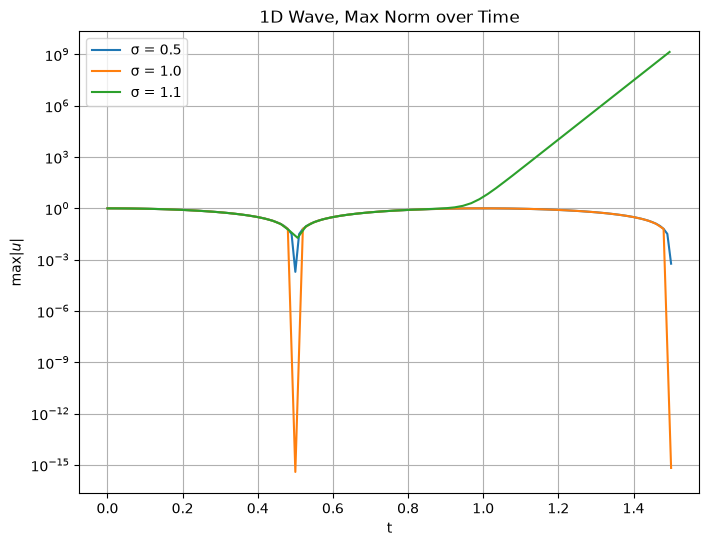

In [4]:
plt.figure(figsize=(8, 6))
for s, d in out.items():
    plt.semilogy(np.arange(len(d['mx']))*d['dt'], d['mx'], label=f"σ = {s}")
plt.xlabel("t")
plt.ylabel(r"$\max |u|$")
plt.title("1D Wave, Max Norm over Time")
plt.legend()
plt.grid(True)
plt.savefig("../figures/09_max_norm.png", dpi=300, bbox_inches="tight")
plt.show()

### Error

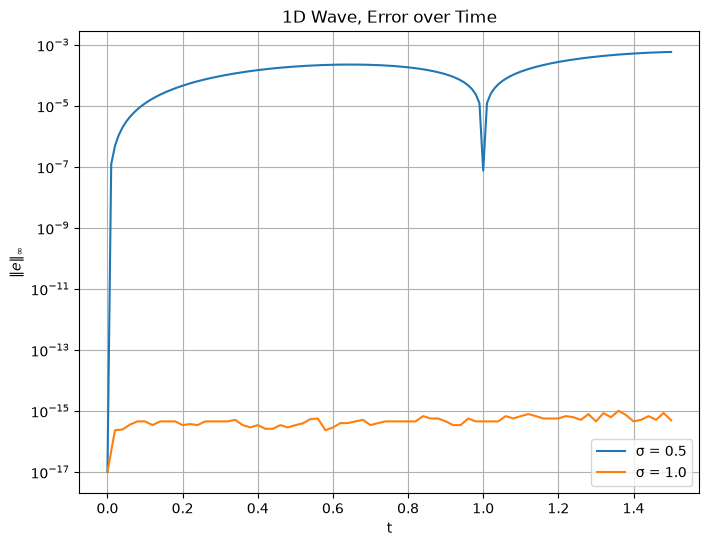

In [5]:
plt.figure(figsize=(8, 6))
for s in [0.5, 1.0]:
    d = out[s]
    plt.semilogy(np.arange(len(d['err']))*d['dt'], d['err']+1e-17, label=f"σ = {s}")
plt.xlabel("t")
plt.ylabel(r"$\|e\|_\infty$")
plt.title("1D Wave, Error over Time")
plt.legend()
plt.grid(True)
plt.savefig("../figures/09_error.png", dpi=300, bbox_inches="tight")
plt.show()

## Conclusion
At $\sigma = 1$ the error is 5e-16, which is machine precision, and at $\sigma = 0.5$ it is 6e-4 at t = 1.5. At $\sigma = 1.1$ rounding noise grows to 1e9 by the last step.